### Questão 1
O gráfico representa 5000 carteiras aleatórias (os pontos) criadas pegando 5 pesos aleatórios para cada ação. A volatilidade e o retorno são representados pelo eixo X e Y, respectivamente. Dessa forma, a borda superior da nuvem de carteiras indica a "fronteira eficiente", ou seja, os maiores retornos para aquele nível de risco

ITUB4    0.015397
MGLU3    0.100757
MULT3    0.017974
PETR4    0.675560
TOTS3    0.190312
dtype: float64


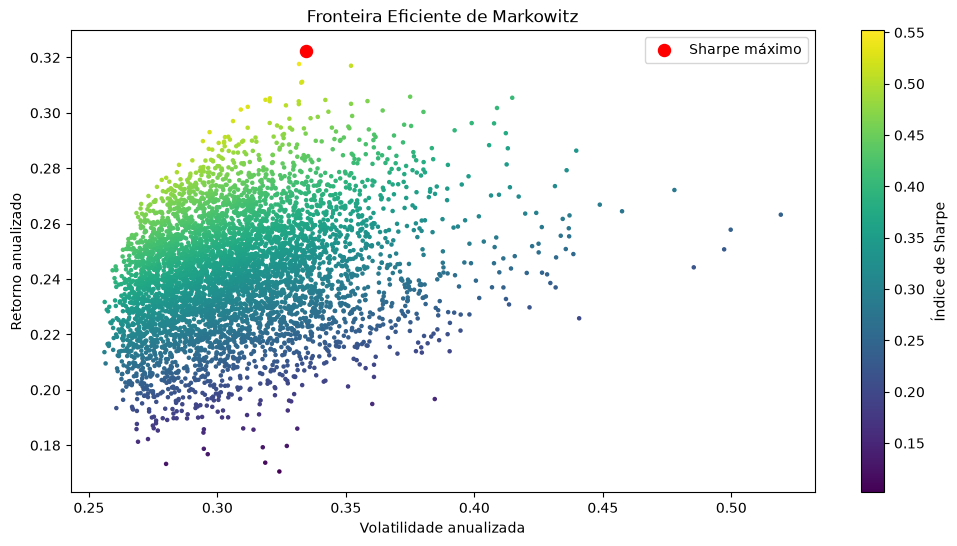

In [85]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm


#Carregando as bases e dados necessários para o gráfico
cotacoes = pd.read_excel('economatica(3).xlsx', index_col=0, header=3, na_values='-')
nomes_novos = []
for cotacao in cotacoes.columns:
    nomes_novos.append(cotacao.split("\n")[-1])
cotacoes.columns = nomes_novos
cotacoes = cotacoes.dropna()
acoes = ['ITUB4', 'MGLU3', 'MULT3', 'PETR4', 'TOTS3']
cotacoes = cotacoes[acoes]
retorno_simples = cotacoes.pct_change().dropna()
retorno_medio_anualizado = retorno_simples.mean() * 252
covariancia_anualizada = retorno_simples.cov() * 252
selic = 0.1375
#Simulação de 5000 carteiras aleatórias
sharpes = []
lista_pesos = []
volatilidades = []
retornos = []
np.random.seed(42)
for x in range(0, 5000):
    peso = np.random.random(5)
    pesos = peso / np.sum(peso)
    lista_pesos.append(pesos)
    retorno_portfolio = pesos @ retorno_medio_anualizado
    retornos.append(retorno_portfolio)
    volatilidade_portfolio = np.sqrt(pesos @ covariancia_anualizada @ pesos)
    volatilidades.append(volatilidade_portfolio)
    sharpe = (retorno_portfolio - selic) / volatilidade_portfolio
    sharpes.append(sharpe)

indice = np.argmax(sharpes)
pesos_max_sharpe = pd.Series(lista_pesos[indice], index=acoes)
print(pesos_max_sharpe)

plt.figure(figsize=(12, 6))
plt.scatter(volatilidades, retornos, c=sharpes, s=5)
plt.colorbar(label='Índice de Sharpe')
plt.scatter(volatilidades[indice], retornos[indice], color='red', marker='.', s=300, label='Sharpe máximo')
plt.title('Fronteira Eficiente de Markowitz')
plt.xlabel('Volatilidade anualizada')
plt.ylabel('Retorno anualizado')
plt.legend()
plt.show()


### Questão 2
O portfólio antigo tem um retorno consideravelmente menor do que o portfólio com sharpe máximo, entretanto a volatilidade do portfólio de sharpe máximo também é consideralmente maior que do antigo portfólio. Por fim, o sharpe do portfólio novo é bem maior que o do portfólio antigo (0,55 > 0,35).

Portfolio Antigo
Retorno anualizado: 0.24161732927586813
Volatilidade anualizada: 0.29778735725684546
Índice de Sharpe: 0.3496364997996391
Portfolio Novo
Retorno anualizado: 0.3221611285313726
Volatilidade anualizada: 0.33459395554955507
Índice de Sharpe: 0.5518961878079215


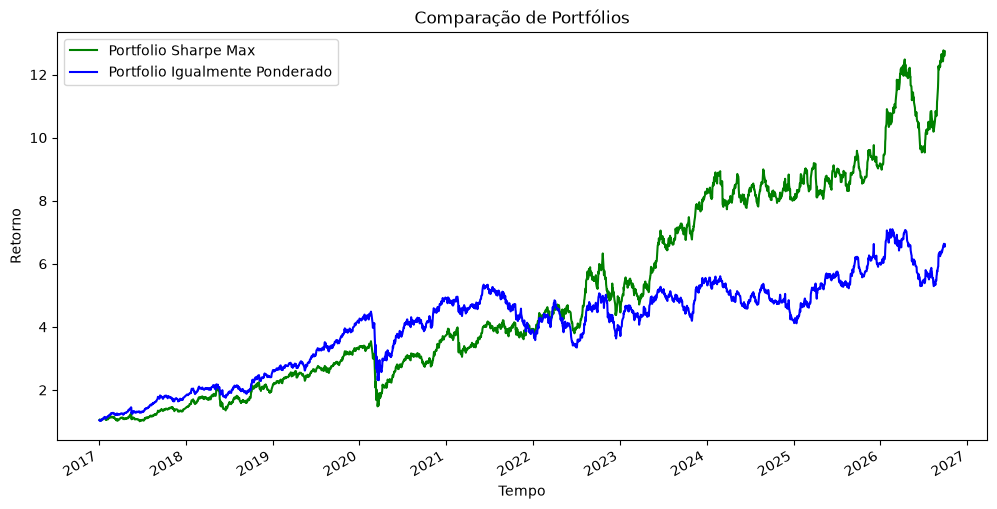

In [86]:
# Criando o portfólio antigo
pesos_iguais = [0.2, 0.2, 0.2, 0.2, 0.2]
portfolio_igual_ret = retorno_simples[acoes] @ pesos_iguais
portf_igual_retorno_anualizado = portfolio_igual_ret.mean() * 252
portf_igual_volatilidade = np.sqrt(pesos_iguais @ covariancia_anualizada @ pesos_iguais)
portf_igual_sharpe = (portf_igual_retorno_anualizado - selic) / portf_igual_volatilidade
portf_igual_acumulado = (1 + portfolio_igual_ret).cumprod()
print("Portfolio Antigo")
print("Retorno anualizado:", portf_igual_retorno_anualizado)
print("Volatilidade anualizada:", portf_igual_volatilidade)
print("Índice de Sharpe:", portf_igual_sharpe)

# Criando o portfólio novo
portf_novo_ret = retorno_simples[acoes] @ pesos_max_sharpe
portf_novo_ret_anualizado = portf_novo_ret.mean() * 252
portf_novo_volatilidade = np.sqrt(pesos_max_sharpe @ covariancia_anualizada @ pesos_max_sharpe)
portf_novo_sharpe = (portf_novo_ret_anualizado - selic) / portf_novo_volatilidade
portf_novo_acumulado = (1 + portf_novo_ret).cumprod()
print("Portfolio Novo")
print("Retorno anualizado:", portf_novo_ret_anualizado)
print("Volatilidade anualizada:", portf_novo_volatilidade)
print("Índice de Sharpe:", portf_novo_sharpe)

# Plotando os dois portfólios no gráfico
grafico_portfolios = portf_novo_acumulado.plot(figsize=(12, 6), label='Portfolio Sharpe Max', color='green')
portf_igual_acumulado.plot(ax=grafico_portfolios, label='Portfolio Igualmente Ponderado', color='blue')
plt.xlabel('Tempo')
plt.ylabel('Retorno')
plt.title('Comparação de Portfólios')
plt.legend()
plt.show()


### Questão 3


In [87]:
# Estimando o retorno do portfólio usando CAPM
ibov = pd.read_csv('ret_acumulado_ibov.csv', index_col=0, parse_dates=True).dropna().squeeze()
retorno_mercado = ibov.pct_change().dropna()
cov_mercado_acao = portf_novo_ret.cov(retorno_mercado)
beta = cov_mercado_acao / retorno_mercado.var()
retorno_mercado_anual = retorno_mercado.mean() * 252
retorno_esperado_capm = selic + beta * (retorno_mercado_anual - selic)
print(f"Retorno esperado do portfólio pelo CAPM: {retorno_esperado_capm}")

#Estimando o retorno pelo Fama-French 3 fatores
nefin = pd.read_csv('nefin_factors.csv', index_col=1, parse_dates=True)
nefin = nefin.loc['2017-01-01':'2026-09-29'].drop(columns=['Unnamed: 0'])
hml = nefin['HML']
smb = nefin['SMB']
selic_diaria = nefin['Risk_Free']
#Rodando a regressão para obter os coeficientes dos fatores
tabela= pd.DataFrame({
    'Excesso': portf_novo_ret - selic_diaria,
    'MKT-RF': retorno_mercado - selic_diaria,
    'SMB': smb,
    'HML': hml
}).dropna()
y = tabela['Excesso']
x = sm.add_constant(tabela[['MKT-RF', 'SMB', 'HML']])
modelo = sm.OLS(y, x).fit()

parametros = modelo.params
b = parametros['MKT-RF']
smb_coef = parametros['SMB']
hml_coef = parametros['HML']
    
retorno_esperado_ff3 = selic + b * (retorno_mercado_anual - selic) + hml_coef * hml.mean() * 252 + smb.mean() * smb_coef * 252
print(f"Retorno esperado do portfólio pelo Fama-French 3 fatores: {retorno_esperado_ff3}")



Retorno esperado do portfólio pelo CAPM: 0.13976872431455067
Retorno esperado do portfólio pelo Fama-French 3 fatores: 0.2231737366638665
